In [1]:
## Imports
%matplotlib inline
import os
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# ISYE 7406 Project Midterm: Data Preparation & Exploratory Analysis

This notebook builds the analysis dataset and produces every figure and table in the midterm report. It loads the TMDB 5000 movies and credits files and the Oscar Award file from the `Data/` folder, then writes figures, tables and the console log to `outputs/`.

In [2]:
## Setup
DATA_DIR = "Data"
OUTPUT_DIR = "outputs"

MIN_YEAR = 1960            # first release year kept (the CPI table starts in 1960)
MAX_YEAR = 2017            # last release year kept
BASE_YEAR = 2017           # all dollar amounts are converted to 2017 dollars
MIN_DOLLARS = 10_000       # budgets and revenues below this are treated as data errors
OSCAR_YEAR_TOLERANCE = 1   # allowed gap between the Oscar film year and the TMDB release year
ERA_ORDER = ["<=1979", "1980s", "1990s", "2000s", "2010s"]

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# Data Loading & Cleaning

In [3]:
## Data Loader Import & Setup
from models import OutputWriter, TMDBDataLoader

writer = OutputWriter(OUTPUT_DIR)
loader = TMDBDataLoader(writer, data_dir=DATA_DIR, min_year=MIN_YEAR, max_year=MAX_YEAR, base_year=BASE_YEAR,
                        min_dollars=MIN_DOLLARS, oscar_year_tolerance=OSCAR_YEAR_TOLERANCE, era_order=ERA_ORDER)

The following code block joins the movies and credits files on movie ID and turns the nested JSON columns into features: cast size, crew size, crew counts by department, genres, number of production companies and an English-language flag.

In [4]:
full = loader.load()
full[["title", "release_year", "budget", "revenue", "cast_size", "crew_size", "primary_genre"]].head()


LOADING DATA
movies:  (4803, 20)   credits: (4803, 4)
merged on movie id: (4803, 22)


,title,release_year,budget,revenue,cast_size,crew_size,primary_genre
0,Avatar,2009.0,237000000,2787965087,83,153,Action
1,Pirates of the Caribbean: At World's End,2007.0,300000000,961000000,34,32,Adventure
2,Spectre,2015.0,245000000,880674609,83,155,Action
3,The Dark Knight Rises,2012.0,250000000,1084939099,158,217,Action
4,John Carter,2012.0,260000000,284139100,27,132,Action


The following code block runs the cleaning funnel and converts budgets and revenues to 2017 dollars using the BLS CPI-U annual averages. TMDB records a missing budget or revenue as zero, so films below `MIN_DOLLARS` are dropped.

In [5]:
analysis = loader.clean()
analysis[["title", "release_year", "era", "budget_real", "revenue_real", "roi"]].head()


CLEANING FUNNEL
                         Step  Films remaining  Dropped
Raw movies x credits (joined)             4803        0
           Status == Released             4795        8
 Release year in [1960, 2017]             4722       73
Budget and revenue >= $10,000             3143     1579
                  Runtime > 0             3143        0
Non-empty cast and crew lists             3139        4
  [table]  cleaning_funnel.csv


,title,release_year,era,budget_real,revenue_real,roi
0,Avatar,2009.0,2000s,2.708098e+08,3.185689e+09,11.763566
1,Pirates of the Caribbean: At World's End,2007.0,2000s,3.547033e+08,1.136233e+09,3.203333
2,Spectre,2015.0,2010s,2.533734e+08,9.107736e+08,3.594590
3,The Dark Knight Rises,2012.0,2010s,2.668772e+08,1.158182e+09,4.339756
4,John Carter,2012.0,2010s,2.775523e+08,3.033210e+08,1.092843


The following code block merges in the Oscar nominations and wins. Films are matched on a normalized title and release year, allowing the year to be off by `OSCAR_YEAR_TOLERANCE`. Oscar films that don't match are saved to `outputs/tables/oscar_unmatched_check.csv` for review.

In [6]:
analysis = loader.merge_oscars()


MERGING OSCAR DATA
Oscar rows (with a film): 10,877   years 1927-2025
Oscar-nominated films in window: 3,016; matched to analysis set: 747
  (Unmatched films are expected: TMDB-5000 is a subset, and films lacking budget/revenue were dropped.
   Review tables/oscar_unmatched_check.csv for title-format mismatches, e.g. subtitles or punctuation.)
Analysis films nominated: 747  |  won >=1 award: 300


# Exploratory Data Analysis

In [7]:
## Exploratory Analysis Import & Setup
from models import ExploratoryAnalysis

eda = ExploratoryAnalysis(full, analysis, writer, has_awards=loader.has_awards, min_dollars=MIN_DOLLARS,
                          era_order=ERA_ORDER)

The following code block produces the data description for Section 2.2: the data dictionary, missing values before cleaning, the share of usable films by era, summary statistics, crew counts by department and the number of films per year.


SECTION 2.2  DATA DESCRIPTION
  [table]  data_dictionary.csv

Full joined dataset: 4,803 films x 44 columns
Analysis dataset:    3,139 films (1960.0-2016.0)

Missing / zero values among released films (pre-cleaning), %:
                       pct_missing_or_zero
budget (0 = missing)                 21.52
revenue (0 = missing)                29.61
runtime                               0.75
release_date                          0.02
cast list empty                       0.86
crew list empty                       0.54
homepage                             64.36
tagline                              17.48
  [table]  missingness.csv

Share of films with usable budget & revenue, by era (selection-bias check):
        films  usable  pct_usable
era                              
<=1979    180     139        77.2
1980s     278     204        73.4
1990s     778     535        68.8
2000s    2044    1324        64.8
2010s    1441     941        65.3
  [table]  usable_by_era.csv

Summary statistics (

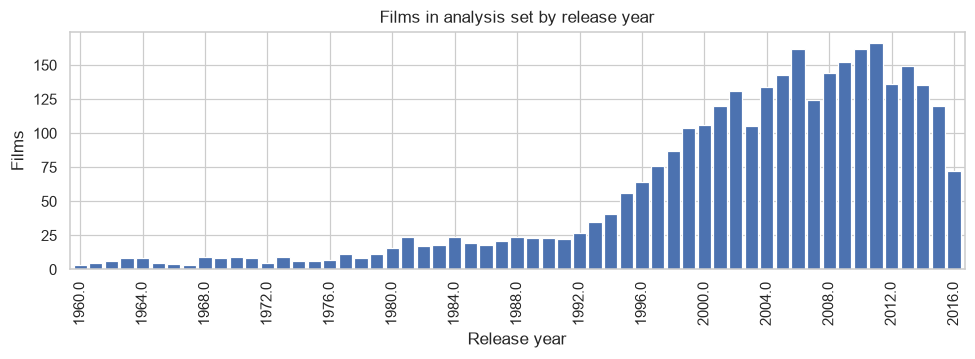

  [figure] fig_films_per_year.png


In [8]:
eda.data_description()

The following code block plots the distributions of the main numeric variables and reports how much a log transform reduces their skew.


2.3  EDA - UNIVARIATE DISTRIBUTIONS


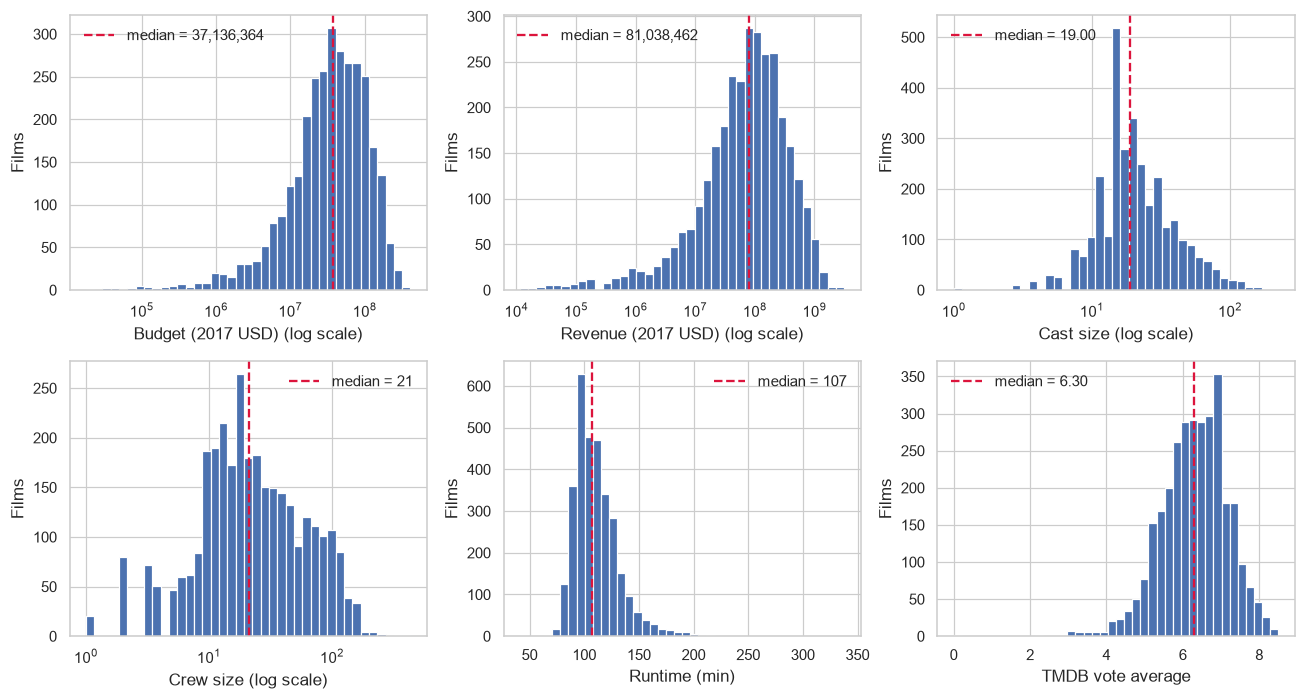

  [figure] fig_distributions.png
  Skewness (raw -> log): budget_real: 1.7 -> -1.29, revenue_real: 3.9 -> -1.25, cast_size: 3.0 -> 0.24, crew_size: 2.3 -> -0.26


In [9]:
eda.distributions()

The following code block plots budget, revenue, cast size, crew size and return on budget over time (RQ1), and saves the era summary, trend tests and crew composition by era.


2.3  EDA - TIME TRENDS (RQ1)


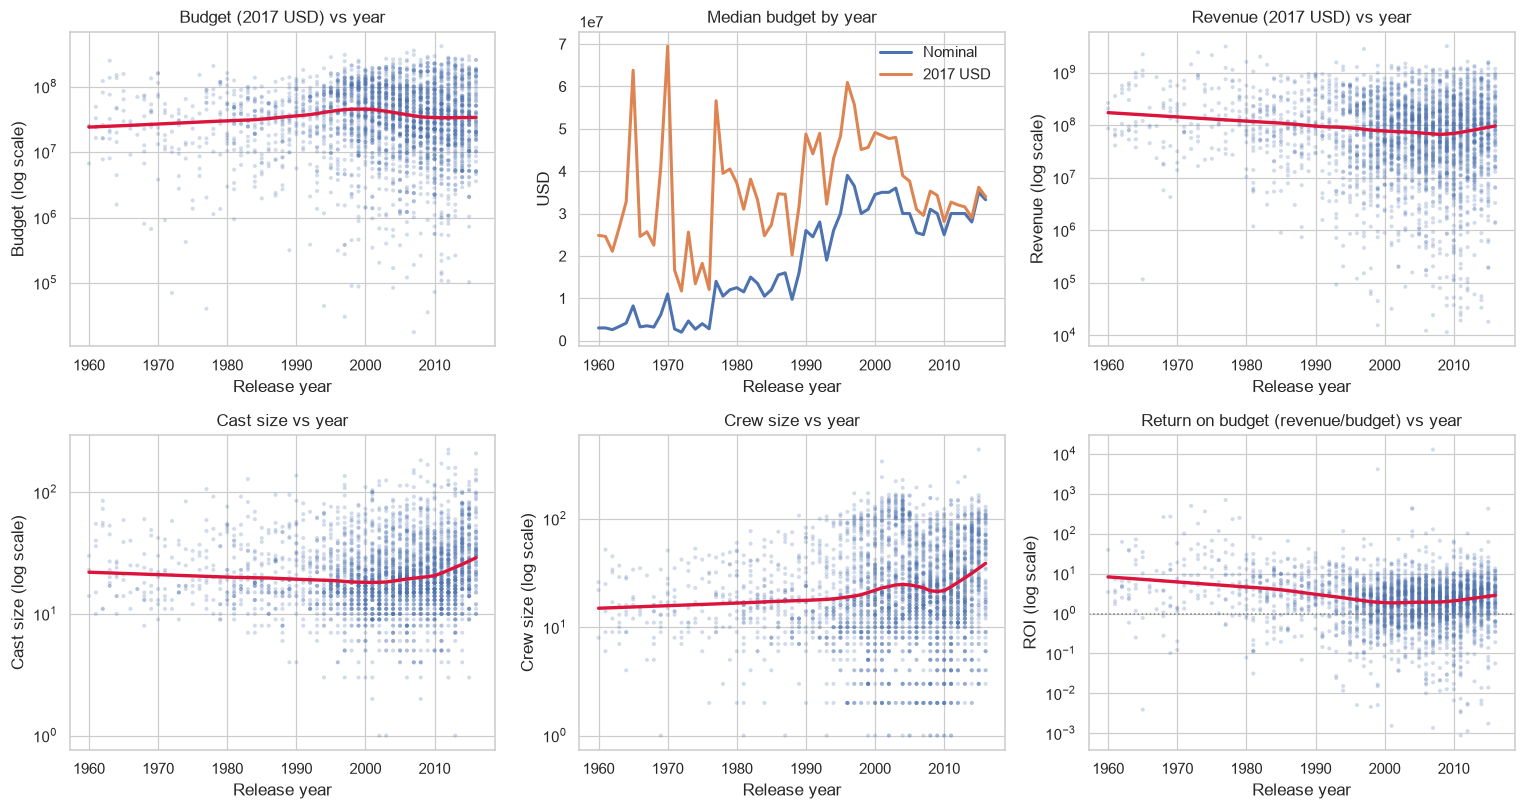

  [figure] fig_time_trends.png
        films  median_budget_nominal  median_budget_real  median_revenue_real  median_roi  pct_budget_ge_100M_real  median_cast  median_crew  median_runtime
era                                                                                                                                                         
<=1979    139              4000000.0         25970860.93         1.335695e+08        5.92                    11.51         20.0         16.0           121.0
1980s     204             13900000.0         29975565.77         9.062063e+07        3.97                     4.90         18.0         17.0           107.0
1990s     535             30000000.0         47493425.61         8.412849e+07        2.11                    18.13         18.0         17.0           108.0
2000s    1321             30000000.0         38925357.33         7.424868e+07        1.98                    16.65         18.0         22.0           105.0
2010s     940             3

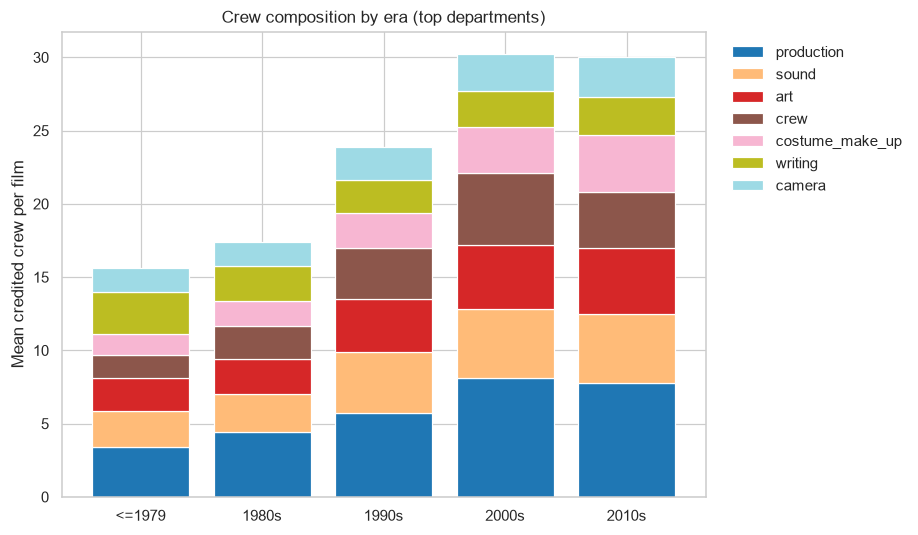

  [figure] fig_crew_composition_by_era.png


In [10]:
eda.time_trends()

The following code block measures how the budget–revenue relationship changes by era (RQ1), fits a preliminary budget × year regression, and summarizes return on budget by budget tier.


2.3  EDA - BUDGET vs REVENUE BY ERA (RQ1)


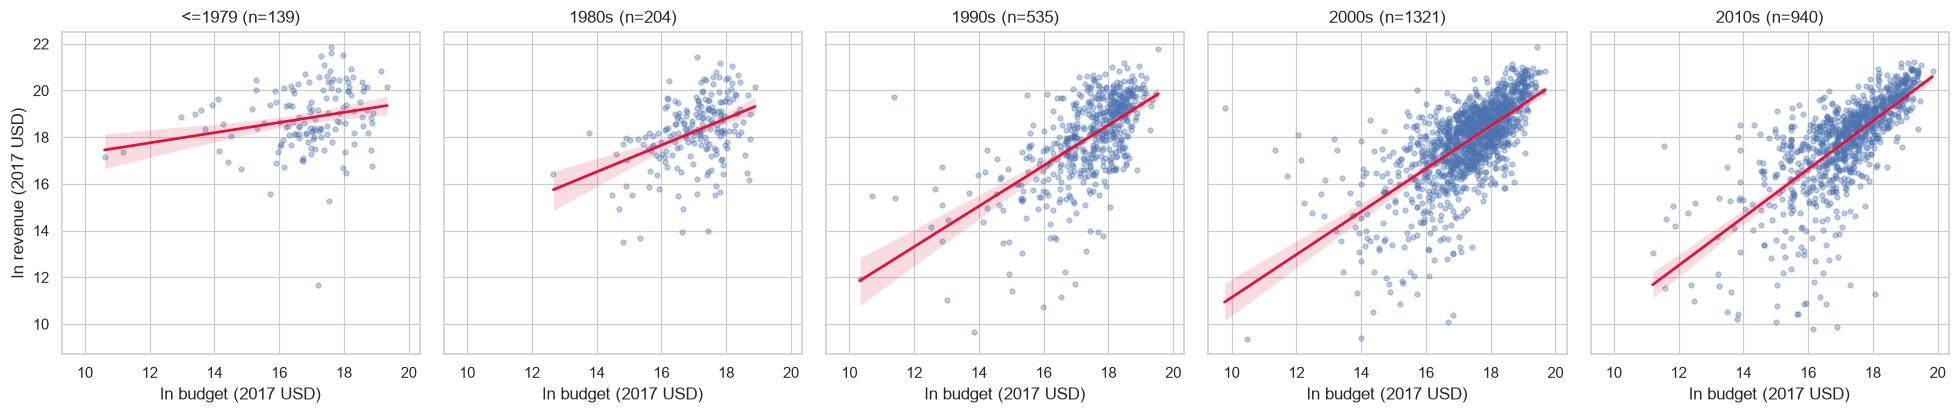

  [figure] fig_budget_revenue_by_era.png
           n  pearson_r  ci_lo  ci_hi  spearman_rho  ols_slope  slope_se  r_squared
era                                                                                
<=1979   139      0.225  0.061  0.378         0.275      0.218     0.080      0.051
1980s    204      0.407  0.286  0.516         0.386      0.572     0.090      0.166
1990s    535      0.616  0.561  0.666         0.616      0.869     0.048      0.380
2000s   1321      0.661  0.630  0.690         0.684      0.919     0.029      0.437
2010s    940      0.703  0.669  0.734         0.768      1.032     0.034      0.494
  [table]  budget_revenue_by_era.csv


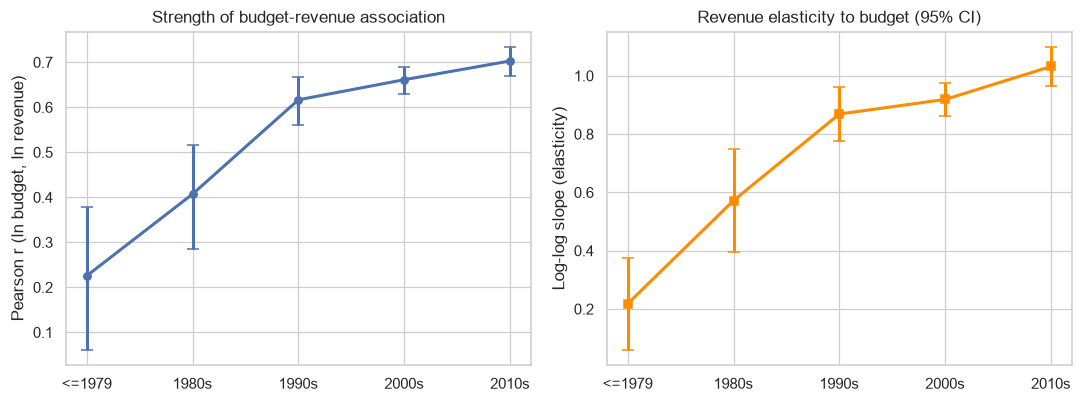

  [figure] fig_correlation_by_era.png

Quick preview of RQ1 interaction (full modeling goes in Section 5):
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 2.8962      0.506      5.718      0.000       1.904       3.889
ln_budget_real            0.8718      0.029     30.360      0.000       0.816       0.928
year_c                   -0.3435      0.036     -9.635      0.000      -0.413      -0.274
ln_budget_real:year_c     0.0189      0.002      9.183      0.000       0.015       0.023

Return on budget by budget tier (2017 USD):
             films  median_roi  pct_unprofitable   iqr
budget_real                                           
<$10M          482        3.24             27.59  8.84
$10-50M       1440        2.25             26.25  3.46
$50-100M       706        2.02             24.79  2.41
>$100M         511        2.38   

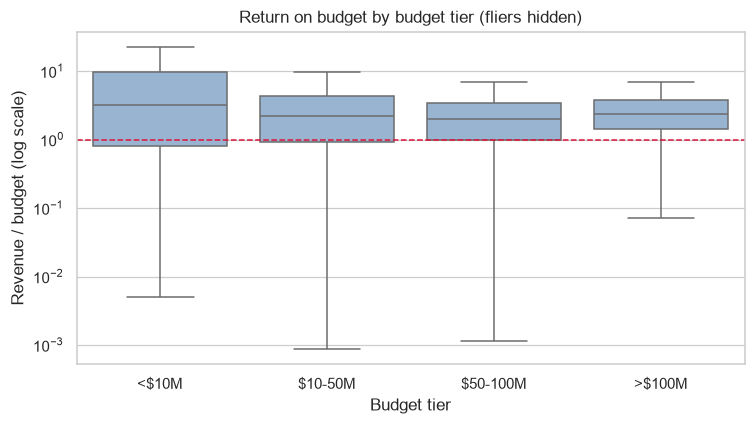

  [figure] fig_roi_by_budget_tier.png


In [11]:
eda.budget_revenue_by_era()

The following code block compares cast and crew size with budget and checks whether they are tied to revenue beyond budget (RQ2), using partial correlations and variance inflation factors.


2.3  EDA - PRODUCTION SCALE vs BUDGET (RQ2)


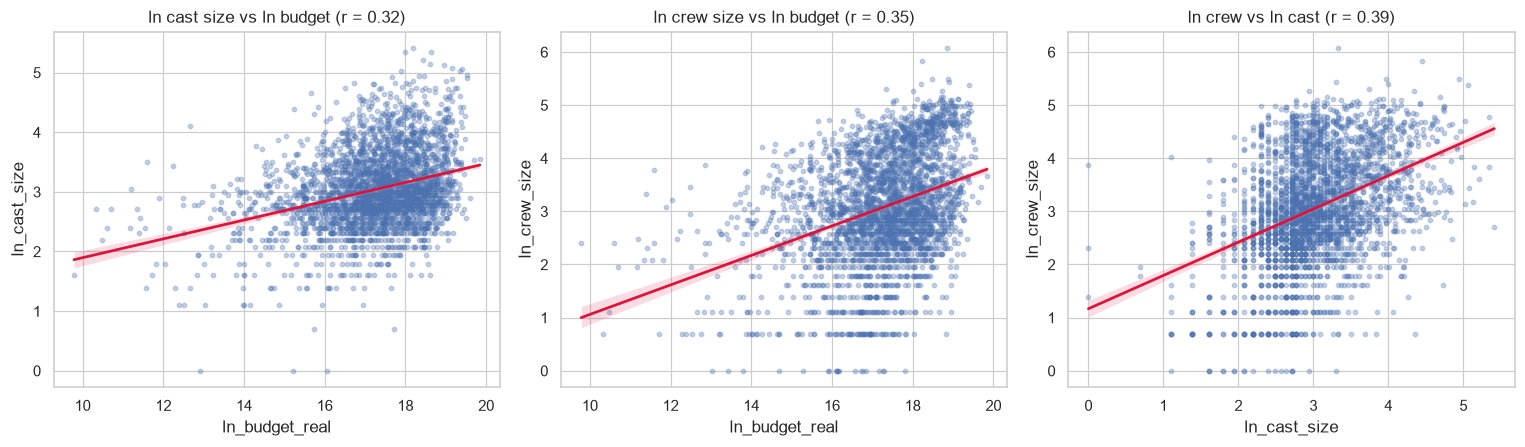

  [figure] fig_scale_vs_budget.png
Does scale carry signal about revenue beyond budget? (partial correlations)
                raw_r_with_ln_revenue  partial_r_given_budget  p_budget  partial_r_given_budget_year  p_budget_year     n
scale_variable                                                                                                           
ln_cast_size                   0.3751                  0.2393       0.0                       0.2543            0.0  3139
ln_crew_size                   0.3795                  0.2199       0.0                       0.2481            0.0  3139
  [table]  partial_correlations.csv

Variance inflation factors (relevant for Lasso/Ridge motivation in RQ2):
ln_budget_real    1.25
ln_cast_size      1.30
ln_crew_size      1.29
release_year      1.06
runtime           1.20
  [table]  vif.csv


In [12]:
eda.scale_vs_budget()

The following code block computes the Spearman correlation matrix of the key variables and lists their correlations with log revenue.


2.3  EDA - CORRELATION MATRIX
  [table]  spearman_correlations.csv


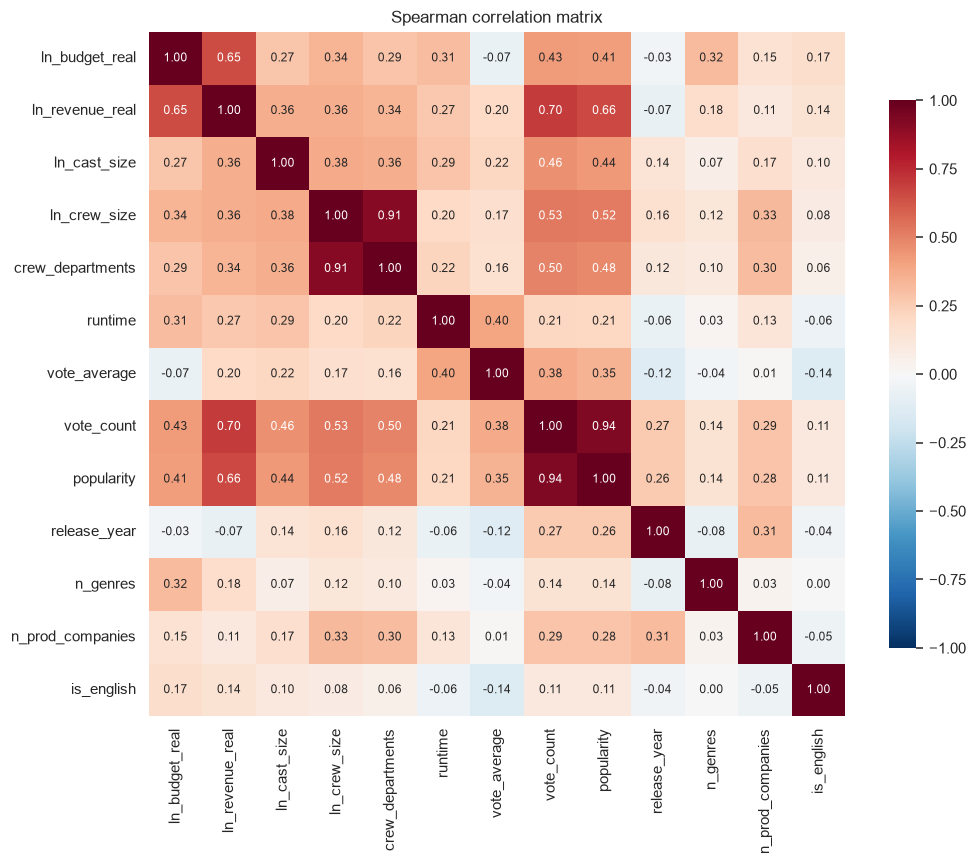

  [figure] fig_correlation_heatmap.png
Spearman correlation with ln revenue (sorted by |rho|):
vote_count          0.697
popularity          0.658
ln_budget_real      0.653
ln_crew_size        0.365
ln_cast_size        0.362
crew_departments    0.340
runtime             0.267
vote_average        0.196
n_genres            0.182
is_english          0.142
n_prod_companies    0.107
release_year       -0.074


In [13]:
eda.correlations()

The following code block summarizes budget, revenue and return on budget by genre.


2.3  EDA - GENRE
                 films  median_budget_real  median_revenue_real  median_roi  median_cast  median_crew
genre                                                                                                
Drama             1385         28610894.94         5.795338e+07        2.02         19.0         20.0
Comedy            1089         34584662.58         8.030728e+07        2.30         19.0         16.0
Thriller           925         40323254.78         7.948953e+07        2.17         19.0         26.0
Action             908         64109166.90         1.236738e+08        2.16         21.0         26.5
Adventure          653         81745414.12         1.902759e+08        2.38         22.0         26.0
Romance            544         30139802.77         6.525617e+07        2.31         19.0         16.0
Crime              516         35427659.21         6.790933e+07        2.00         20.0         22.0
Science Fiction    425         62846153.85         1.157788e+08 

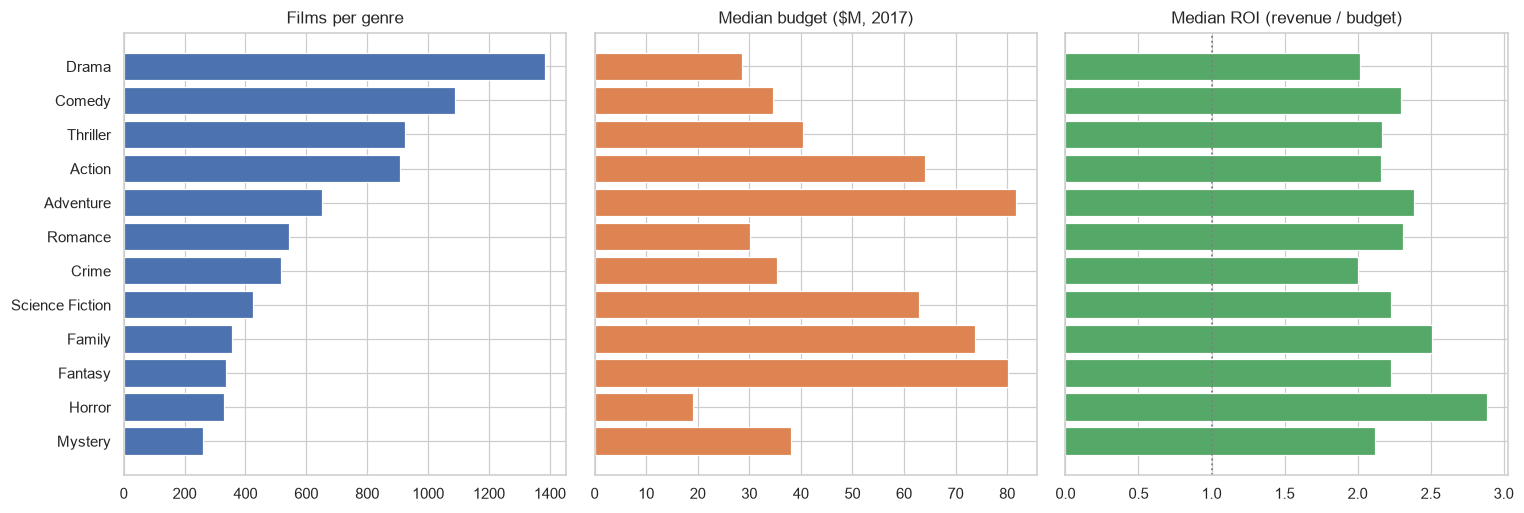

  [figure] fig_genre_summary.png


In [14]:
eda.genre()

The following code block describes the two awards stages (RQ4): how nomination rates vary with budget, and how win rates vary with budget among nominees.


2.3  EDA - AWARDS (RQ4)
                        stage    n     rate
                    All films 3139      NaN
   Nominated (>=1 nomination)  747 0.237974
Won (>=1 win) among nominated  300 0.401606
  [table]  awards_class_balance.csv
Budget quartile edges ($M, 2017): 0.0, 16.9, 37.1, 75.3, 414.1
  [table]  awards_nomination_by_budget_quartile.csv

P(nominated) by budget quartile:
                n  events   rate  ci_lo  ci_hi
budget_q                                      
Q1 (lowest)   788     152  0.193  0.167  0.222
Q2            782     158  0.202  0.175  0.232
Q3            786     183  0.233  0.205  0.264
Q4 (highest)  783     254  0.324  0.293  0.358
  [table]  awards_win_by_budget_quartile.csv

P(win | nominated) by budget quartile:
                n  events   rate  ci_lo  ci_hi
budget_q                                      
Q1 (lowest)   152      65  0.428  0.352  0.507
Q2            158      71  0.449  0.374  0.527
Q3            183      74  0.404  0.336  0.477
Q4 (highest)

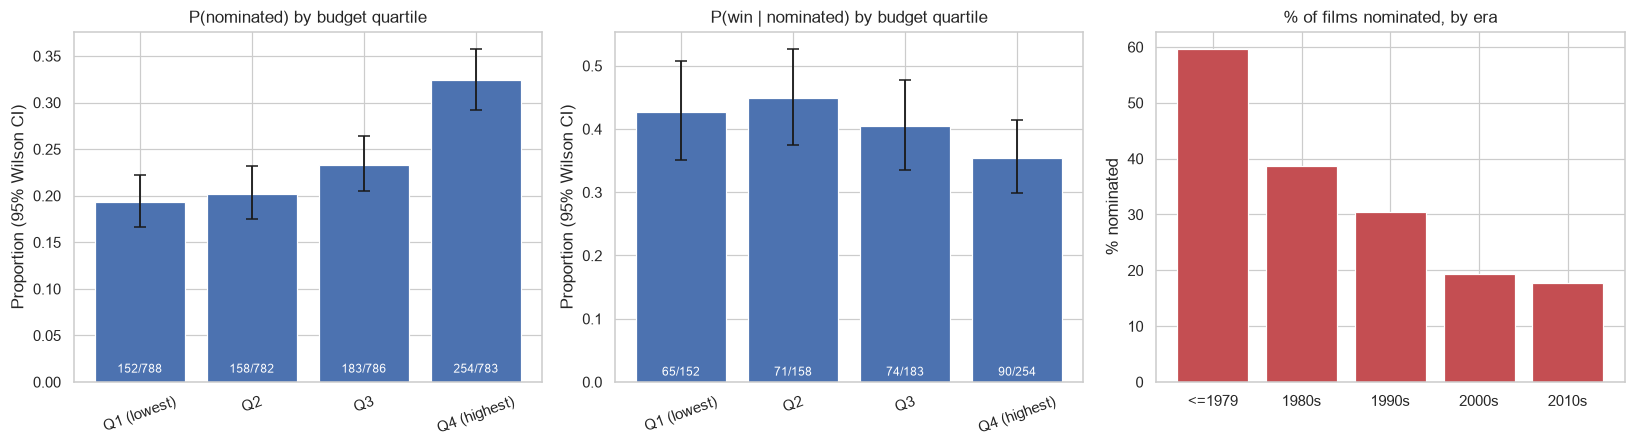

  [figure] fig_awards_by_budget_quartile.png

Chi-square test (budget quartile x nominated): chi2=46.76, p=3.911e-10


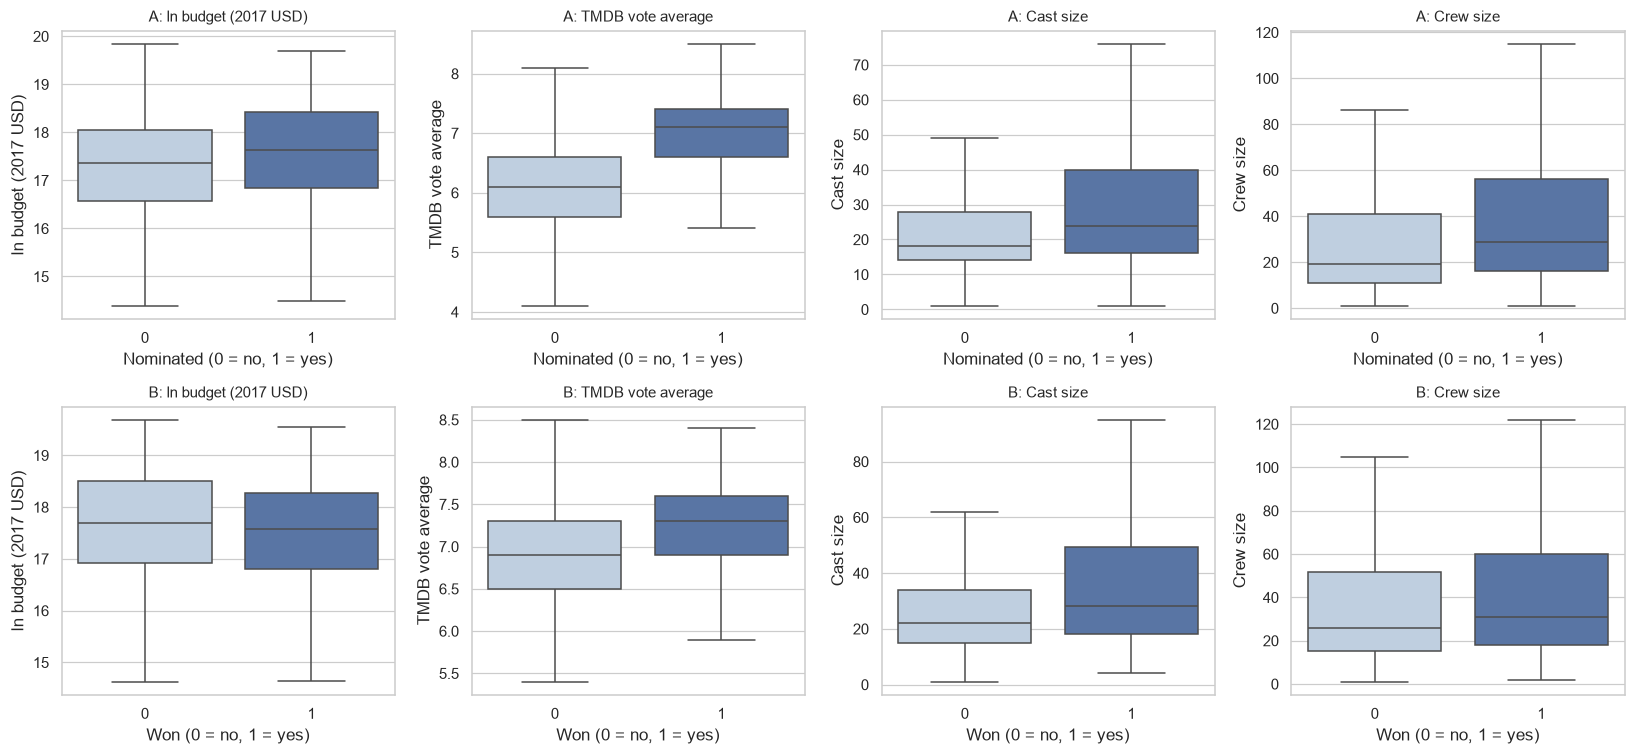

  [figure] fig_awards_distributions.png

Mann-Whitney tests:
                         stage       variable  n_group0  n_group1  median_group0  median_group1  mannwhitney_p
           A: nominated vs not ln_budget_real      2392       747        17.3603        17.6333         0.0000
           A: nominated vs not   vote_average      2392       747         6.1000         7.1000         0.0000
           A: nominated vs not      cast_size      2392       747        18.0000        24.0000         0.0000
           A: nominated vs not      crew_size      2392       747        19.0000        29.0000         0.0000
B: won vs lost (nominees only) ln_budget_real       447       300        17.6998        17.5708         0.0948
B: won vs lost (nominees only)   vote_average       447       300         6.9000         7.3000         0.0000
B: won vs lost (nominees only)      cast_size       447       300        22.0000        28.0000         0.0000
B: won vs lost (nominees only)      crew_size      

In [15]:
if loader.has_awards:
    eda.awards()
else:
    print("Oscar file not found, skipping the awards analysis.")

# Save Outputs

The following code block saves the analysis-ready dataset and the console log.

In [16]:
output_file = os.path.join(OUTPUT_DIR, "tmdb_clean.csv")
clean_df = eda.save_clean_dataset(output_file)
writer.save_log("eda_summary.txt")

print(f"Saved {output_file} ({len(clean_df):,} rows) and eda_summary.txt")

Saved outputs/tmdb_clean.csv (3,139 rows) and eda_summary.txt


# LaTeX Table Export

In [17]:
## LaTeX Exporter Import & Setup
from models import LatexTableExporter

TEX_DIR = os.path.join(OUTPUT_DIR, "tables_tex")
COLUMN_FORMATS = {"data_dictionary": r"p{0.26\textwidth}p{0.46\textwidth}p{0.2\textwidth}"}

The following code block converts every saved CSV table into a booktabs LaTeX table that the report reads with `\input{}`.

In [18]:
exporter = LatexTableExporter(writer.tables_dir, TEX_DIR, column_formats=COLUMN_FORMATS)
table_count = exporter.export_all()

print(f"Wrote {table_count} tables to {TEX_DIR}")

Wrote 19 tables to outputs/tables_tex
